<a href="https://colab.research.google.com/github/Harsh-L/Quantum-Computing-Introduction/blob/main/Quantum_Computing_Arithmetic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit
!pip install qiskit-aer
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.4/39.4 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.5/108.5 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 1.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=1dcf0defd637a070341abc0e3ef57514d1dfd76c3f513e042694b80305770c6d
  Stored in directory: /root/.cache/pip/wheels/d3/31/8b/e09b0386afd80cfc556c00408c9aeea5c35c4d484a9c762fd5
Successfully built pylatexenc


In [ ]:
from qiskit.circuit.library import CDKMRippleCarryAdder, arithmetic, RGQFTMultiplier, IntegerComparator, QFT
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import HGate
import math
from qiskit_aer import Aer, QasmSimulator as sim, jobs

# Addition

In [ ]:
bit_size = int(input('Enter upto to how many bits you need to get the result : '))
print(f'Summation will be upto : {2**bit_size}')

Enter upto to how many bits you need to get the result : 1
Summation will be upto : 2


In [ ]:
user_input_1 = int(input("Enter First number : "))
user_input_2 = int(input("Enter Second number : "))
data = user_input_1 + user_input_2 # Addition
# data = user_input_1 * user_input_2 # Multiplication
print(data)
exponent = 1
bit_size = 0
while bit_size<data:
  bit_size = pow(2,exponent)
  print(bit_size)
  exponent = exponent + 1

print(f'final size {bit_size}')

Enter First number : 2
Enter Second number : 2
4
2
4
final size 4


In [ ]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(len( bin(num_1)) - 2 , len(bin(num_2)) - 2)
print(f'Each Data : {num_qubits} Bit')

result_qubits = num_qubits + 1 # result addition of 2 binary numbers will be at max 1.1 times the length of longest binary number inputted
print(f'Resut : {result_qubits} Bit')

total_qubits = 3*num_qubits # Total Circuit will be 4 times the length on longest binary number
print(f'Total Circuit : {total_qubits} Bit')


print(bin(num_1))
print(bin(num_2))
print(bin(num_1*num_2))
print(f'Length on Num 1 (Binary) : {len(bin(num_1)) -2}')
print(f'Length on Num 1 (Binary) : {len(bin(num_2)) -2}')

Enter First Number : 2
Enter Second Number : 3
Each Data : 2 Bit
Resut : 3 Bit
Total Circuit : 6 Bit
0b10
0b11
0b110
Length on Num 1 (Binary) : 2
Length on Num 1 (Binary) : 2


In [ ]:
adder = CDKMRippleCarryAdder(num_qubits)  # Adder of 3-bit numbers
reg_a = None
reg_b = None
num_a = None
num_b = None
# Create the number A=2 or take user input
reg_a = QuantumRegister(size= num_qubits, name= 'a')
num_a = QuantumCircuit(reg_a)
num_a.initialize(num_1)
# num_a.initialize(13)

# Create the number B=3 or take user input
reg_b = QuantumRegister(size= num_qubits, name='b')
num_b = QuantumCircuit(reg_b)
num_b.initialize(num_2)
# num_b.initialize(11)

In [ ]:
reg_res = ClassicalRegister(num_qubits+1)
circuit = QuantumCircuit(*adder.qregs, reg_res)

# qreg = QuantumRegister(total_qubits, 'qr')

ckt = circuit.compose(num_a, qubits=reg_a).compose(num_b, qubits=reg_b).compose(adder)
print(adder.qregs)
ckt.measure(reg_b[0], reg_res[0])
ckt.measure(reg_b[1], reg_res[1])
# ckt.measure(reg_b[2], reg_res[2])
ckt.measure(adder.qregs[-1], reg_res[2])
# ckt.measure(adder.qregs[2:-1], reg_res[0:3])
print(adder.qregs[2:-1])
# ckt.measure(adder.qregs[1:num_qubits], reg_res[:num_qubits])
# ckt.measure(qreg[4], reg_res[2])
ckt.draw()

[QuantumRegister(1, 'cin'), QuantumRegister(2, 'a'), QuantumRegister(2, 'b'), QuantumRegister(1, 'cout')]
[QuantumRegister(2, 'b')]


┌───────────────────────┐         
 cin: ──────────────────┤0                      ├─────────
      ┌────────────────┐│                       │         
 a_0: ┤0               ├┤1                      ├─────────
      │  Initialize(2) ││                       │         
 a_1: ┤1               ├┤2                      ├─────────
      ├────────────────┤│  CDKMRippleCarryAdder │┌─┐      
 b_0: ┤0               ├┤3                      ├┤M├──────
      │  Initialize(3) ││                       │└╥┘┌─┐   
 b_1: ┤1               ├┤4                      ├─╫─┤M├───
      └────────────────┘│                       │ ║ └╥┘┌─┐
cout: ──────────────────┤5                      ├─╫──╫─┤M├
                        └───────────────────────┘ ║  ║ └╥┘
c3: 3/════════════════════════════════════════════╩══╩══╩═
                                                  0  1  2

In [ ]:
ckt.decompose().draw('mpl')

In [ ]:
# Note the lesser the bit size the faster the code execute
result = Sampler().run(ckt).result()  # Addition
# result = Sampler().run(new_ckt).result() # Multiplication
print(f' Length of Result List : {len(result.quasi_dists)}')
print(f'Result : {result.quasi_dists[0]}')

 Length of Result List : 1
Result : {5: 1.0}


<ipython-input-11-ea506788fdbd>:2: DeprecationWarning: The class ``qiskit.primitives.sampler.Sampler`` is deprecated as of qiskit 1.2. It will be removed no earlier than 3 months after the release date. All implementations of the `BaseSamplerV1` interface have been deprecated in favor of their V2 counterparts. The V2 alternative for the `Sampler` class is `StatevectorSampler`.
  result = Sampler().run(ckt).result()  # Addition


# Subtraction

In [ ]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(len( bin(num_1)) - 2 , len(bin(num_2)) - 2)
print(f'Each Data : {num_qubits} Bit')

result_qubits = num_qubits # result subtraction of 2 binary numbers will be at max 1 times the length of longest binary number inputted
print(f'Resut : {result_qubits} Bit')

total_qubits = 3 * num_qubits # Total Circuit will be 3 times the length on longest binary number
print(f'Total Circuit : {total_qubits} Bit')


print(bin(num_1))
print(bin(num_2))
print(bin((num_1-num_2)))
print(f'Length on Num 1 (Binary) : {len(bin(num_1)) -2}')
print(f'Length on Num 2 (Binary) : {len(bin(num_2)) -2}')

Enter First Number : 20
Enter Second Number : 2
Each Data : 5 Bit
Resut : 5 Bit
Total Circuit : 15 Bit
0b10100
0b10
0b10010
Length on Num 1 (Binary) : 5
Length on Num 2 (Binary) : 2


In [ ]:
q = QuantumRegister(total_qubits,'q')
adder = CDKMRippleCarryAdder(num_qubits)

# creating ckt of num_1
reg_a = QuantumRegister(size= num_qubits, name= 'a')
num_a = QuantumCircuit(reg_a)
num_a.initialize(num_1)

# creating ckt of inverse of num_2
reg_b = QuantumRegister(size= num_qubits, name= 'b')
num_b = QuantumCircuit(reg_b)
num_b.initialize(-(num_2-1))

reg_res = ClassicalRegister(num_qubits)
circuit = QuantumCircuit(*adder.qregs, reg_res)
circuit = circuit.compose(num_a, qubits=reg_a).compose(num_b, qubits=reg_b)

circuit.x(reg_b[:(num_qubits)])

circuit = circuit.compose(adder)
circuit.measure(reg_b, reg_res)

circuit.draw()

In [ ]:
circuit.decompose().draw()

In [ ]:
# Getting Quantum Simulator
backend = Aer.get_backend('aer_simulator')

# Creating job to execute circuit, NOTE : shots is number of time we need to run the circuit
# job = execute(ckt, backend, shots=2000)
job = execute(circuit, backend, shots=2000)

# Getting the Result afeter the job is completed
result = job.result()
# Finding the count of results as there may be multiple results (due to inaccuracy)
counts = result.get_counts()
print(counts)

# Getting the most frequent Result
most_likely_result = counts.most_frequent()
print(most_likely_result)

# Converting the Binary Result into Integer
multiplication_result = int(most_likely_result,2)
print(f"Most likely subtraction : {multiplication_result}")

{'10010': 2000}
10010
Most likely subtraction : 18


# Multiplication

In [ ]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(len( bin(num_1)) - 2 , len(bin(num_2)) - 2)
print(f'Each Data : {num_qubits} Bit')

result_qubits = 2 * num_qubits # result multiplication of 2 binary numbers will be at max 2 times the length of longest binary number inputted
print(f'Resut : {result_qubits} Bit')

total_qubits = 4 * num_qubits # Total Circuit will be 4 times the length on longest binary number
print(f'Total Circuit : {total_qubits} Bit')


print(bin(num_1))
print(bin(num_2))
print(bin(num_1*num_2))
print(f'Length on Num 1 (Binary) : {len(bin(num_1)) -2}')
print(f'Length on Num 1 (Binary) : {len(bin(num_2)) -2}')

Enter First Number : 2
Enter Second Number : 3
Each Data : 2 Bit
Resut : 4 Bit
Total Circuit : 8 Bit
0b10
0b11
0b110
Length on Num 1 (Binary) : 2
Length on Num 1 (Binary) : 2


In [ ]:
# Creating Multiplier Unit
# num_state_qubits -> bit length of longest of input number
# num_result_qubits -> bit length of result number
multiplier = None
multiplier = RGQFTMultiplier(num_state_qubits = num_qubits, num_result_qubits = result_qubits)

# creating quantum register to hold 2 numbers and their multiplication (in Binary) using "total_qubits" length
qreg = QuantumRegister(total_qubits, 'qr')

reg_a = QuantumRegister(size= num_qubits, name= 'a')
num_a = QuantumCircuit(reg_a)
num_a.initialize(num_1)

reg_b = QuantumRegister(size= num_qubits, name= 'b')
num_b = QuantumCircuit(reg_b)
num_b.initialize(-num_2)

# Composing / Combining Quantum Register with Multiplier Unit

reg_res = ClassicalRegister(result_qubits)
# reg_res = ClassicalRegister(num_qubits)
circuit = None
circuit = QuantumCircuit(*multiplier.qregs, reg_res)
circuit = circuit.compose(num_a, qubits=reg_a).compose(num_b, qubits=reg_b)
# circuit.x(reg_a[:(num_qubits)])

# circuit.x(reg_b[:(num_qubits)])
circuit = circuit.compose(multiplier)

# # Measuring the result_qubits from last using Classical Register

# print(creg[0:result_qubits])
print(multiplier.data[0][1][-4:])

circuit.measure(multiplier.data[0][1][-result_qubits:], reg_res[0:result_qubits])

# Drawing the Circuit
print(circuit.draw())

[Qubit(QuantumRegister(4, 'out'), 0), Qubit(QuantumRegister(4, 'out'), 1), Qubit(QuantumRegister(4, 'out'), 2), Qubit(QuantumRegister(4, 'out'), 3)]
        ┌────────────────┐┌──────────────────┐            
  a_0: ─┤0               ├┤0                 ├────────────
        │  Initialize(2) ││                  │            
  a_1: ─┤1               ├┤1                 ├────────────
       ┌┴────────────────┤│                  │            
  b_0: ┤0                ├┤2                 ├────────────
       │  Initialize(-3) ││                  │            
  b_1: ┤1                ├┤3                 ├────────────
       └─────────────────┘│  RGQFTMultiplier │┌─┐         
out_0: ───────────────────┤4                 ├┤M├─────────
                          │                  │└╥┘┌─┐      
out_1: ───────────────────┤5                 ├─╫─┤M├──────
                          │                  │ ║ └╥┘┌─┐   
out_2: ───────────────────┤6                 ├─╫──╫─┤M├───
                         

<ipython-input-7-c36667d20a8d>:33: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  print(multiplier.data[0][1][-4:])
<ipython-input-7-c36667d20a8d>:35: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  circuit.measure(multiplier.data[0][1][-result_qubits:], reg_res[0:result_qubits])


In [ ]:
# Getting Quantum Simulator
backend = Aer.get_backend('aer_simulator')


# Creating job to execute circuit, NOTE : shots is number of time we need to run the circuit
job = execute(circuit, backend, shots=2000)

# Getting the Result afeter the job is completed
result = job.result()
# Finding the count of results as there may be multiple results (due to inaccuracy)
counts = result.get_counts()
print(counts)

# Getting the most frequent Result
most_likely_result = counts.most_frequent()
print(most_likely_result)

# Converting the Binary Result into Integer
multiplication_result = int(most_likely_result,2)
print(f"Most likely product : {multiplication_result}")

NameError: name 'execute' is not defined

# Division

In [ ]:
num_1 = int(input('Enter First Number : '))
num_2 = int(input('Enter Second Number : '))

num_qubits = max(len( bin(num_1)) - 2 , len(bin(num_2)) - 2)
print(f'Each Data : {num_qubits} Bit')

result_qubits = num_qubits # result division of 2 binary numbers will be at max 1 times the length of longest binary number inputted
print(f'Resut : {result_qubits} Bit')

total_qubits = 3 * num_qubits # Total Circuit will be 3 times the length on longest binary number
print(f'Total Circuit : {total_qubits} Bit')


print(bin(num_1))
print(bin(num_2))
print(bin(int(num_1/num_2)))
print(f'Length on Num 1 (Binary) : {len(bin(num_1)) -2}')
print(f'Length on Num 1 (Binary) : {len(bin(num_2)) -2}')

Enter First Number : 6
Enter Second Number : 2
Each Data : 3 Bit
Resut : 3 Bit
Total Circuit : 9 Bit
0b110
0b10
0b11
Length on Num 1 (Binary) : 3
Length on Num 1 (Binary) : 2


In [ ]:
# Creating Multiplier Unit
# num_state_qubits -> bit length of longest of input number
# num_result_qubits -> bit length of result number
divider = None
divider = RGQFTMultiplier(num_state_qubits = num_qubits, num_result_qubits = result_qubits)
# divider = QFT(num_qubits= total_qubits+2, inverse=True)

# creating quantum register to hold 2 numbers and their multiplication (in Binary) using "total_qubits" length
qreg = QuantumRegister(total_qubits, 'qr')

reg_a = QuantumRegister(size= num_qubits, name= 'a')
num_a = QuantumCircuit(reg_a)
num_a.initialize(num_1)

reg_b = QuantumRegister(size= num_qubits, name= 'b')
num_b = QuantumCircuit(reg_b)
num_b.initialize(num_2)

# Composing / Combining Quantum Register with Multiplier Unit

reg_res = ClassicalRegister(result_qubits)
# reg_res = ClassicalRegister(num_qubits)
ckt = None
ckt = QuantumCircuit(*divider.qregs, reg_res)

print(num_a.data)
print(divider.qregs)

circuit = ckt.compose(num_a, qubits=reg_a).compose(num_b, qubits=reg_b)
circuit = circuit.compose(divider)

# # Measuring the result_qubits from last using Classical Register
# print(reg_res[0:result_qubits])
# print(divider.data[0][1][-result_qubits:])

circuit.measure(divider.data[0][1][-result_qubits:], reg_res[0:result_qubits])

# Drawing the Circuit
print(circuit.draw())

[CircuitInstruction(operation=Instruction(name='initialize', num_qubits=3, num_clbits=0, params=[(6+0j)]), qubits=(Qubit(QuantumRegister(3, 'a'), 0), Qubit(QuantumRegister(3, 'a'), 1), Qubit(QuantumRegister(3, 'a'), 2)), clbits=())]
[QuantumRegister(3, 'a'), QuantumRegister(3, 'b'), QuantumRegister(3, 'out')]
       ┌────────────────┐┌──────────────────┐         
  a_0: ┤0               ├┤0                 ├─────────
       │                ││                  │         
  a_1: ┤1 Initialize(6) ├┤1                 ├─────────
       │                ││                  │         
  a_2: ┤2               ├┤2                 ├─────────
       ├────────────────┤│                  │         
  b_0: ┤0               ├┤3                 ├─────────
       │                ││                  │         
  b_1: ┤1 Initialize(2) ├┤4 RGQFTMultiplier ├─────────
       │                ││                  │         
  b_2: ┤2               ├┤5                 ├─────────
       └────────────────┘│   

In [ ]:
circuit.decompose().draw()

In [ ]:
# Getting Quantum Simulator
# backend = Aer.aer.get_backend('aer_simulator')
backend = Aer.aer.get_backend('aer_simulator')

# Creating job to execute circuit, NOTE : shots is number of time we need to run the circuit
job = execute(circuit, backend, shots=2000)

# Getting the Result afeter the job is completed
result = job.result()
# Finding the count of results as there may be multiple results (due to inaccuracy)
counts = result.get_counts()
print(counts)

# Getting the most frequent Result
most_likely_result = counts.most_frequent()
print(most_likely_result)

# Converting the Binary Result into Integer
multiplication_result = int(most_likely_result,2)
print(f"Most likely product : {multiplication_result}")

{'100': 2000}
100
Most likely product : 4


# Negation

In [ ]:
qc = QuantumCircuit(2)
qc.qubits

[Qubit(QuantumRegister(2, 'q'), 0), Qubit(QuantumRegister(2, 'q'), 1)]

In [ ]:
qc.x(0)
qc.data

[CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(Qubit(QuantumRegister(2, 'q'), 0),), clbits=())]

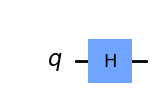

In [ ]:
qc.draw('mpl')

In [ ]:
# testing
# inv_reg = ClassicalRegister(3)

multiplier = arithmetic.HRSCumulativeMultiplier(3)
new_adder = CDKMRippleCarryAdder(3)


# multiplier

reg_a = QuantumRegister(size= 3, name= 'a')
num_a = QuantumCircuit(reg_a)
# num_a.initialize(user_input_1)
num_a.initialize(5)

# Create the number B=3 or take user input
reg_b = QuantumRegister(size= 3, name='b')
num_b = QuantumCircuit(reg_b)
# num_b.initialize(user_input_2)
num_b.initialize(2)

reg_res = ClassicalRegister(3)
circuit = QuantumCircuit(*multiplier.qregs, reg_res)

ckt = circuit.compose(num_a, qubits=reg_a).compose(num_b, qubits=reg_b).compose(new_adder).compose(multiplier)
ckt.measure(reg_b, reg_res)
ckt.draw()

┌────────────────┐┌───────────────────────┐»
   a_0: ┤0               ├┤0                      ├»
        │                ││                       │»
   a_1: ┤1 Initialize(5) ├┤1                      ├»
        │                ││                       │»
   a_2: ┤2               ├┤2                      ├»
        ├────────────────┤│                       │»
   b_0: ┤0               ├┤3                      ├»
        │                ││  CDKMRippleCarryAdder │»
   b_1: ┤1 Initialize(2) ├┤4                      ├»
        │                ││                       │»
   b_2: ┤2               ├┤5                      ├»
        └────────────────┘│                       │»
 out_0: ──────────────────┤6                      ├»
                          │                       │»
 out_1: ──────────────────┤7                      ├»
                          └───────────────────────┘»
 out_2: ───────────────────────────────────────────»
                                                   »
 out_3: ───────────────────────────────────────────»
                                                   »
 out_4: ───────────────────────────────────────────»
                                                   »
 out_5: ───────────────────────────────────────────»
                                                   »
helper: ───────────────────────────────────────────»
                                                   »
  c5: 3/═══════════════════════════════════════════»
                                                   »
«        ┌───────────────────────────┐         
«   a_0: ┤0                          ├─────────
«        │                           │         
«   a_1: ┤1                          ├─────────
«        │                           │         
«   a_2: ┤2                          ├─────────
«        │                           │┌─┐      
«   b_0: ┤3                          ├┤M├──────
«        │                           │└╥┘┌─┐   
«   b_1: ┤4                          ├─╫─┤M├───
«        │                           │ ║ └╥┘┌─┐
«   b_2: ┤5                          ├─╫──╫─┤M├
«        │                           │ ║  ║ └╥┘
« out_0: ┤6  HRSCumulativeMultiplier ├─╫──╫──╫─
«        │                           │ ║  ║  ║ 
« out_1: ┤7                          ├─╫──╫──╫─
«        │                           │ ║  ║  ║ 
« out_2: ┤8                          ├─╫──╫──╫─
«        │                           │ ║  ║  ║ 
« out_3: ┤9                          ├─╫──╫──╫─
«        │                           │ ║  ║  ║ 
« out_4: ┤10                         ├─╫──╫──╫─
«        │                           │ ║  ║  ║ 
« out_5: ┤11                         ├─╫──╫──╫─
«        │                           │ ║  ║  ║ 
«helper: ┤12                         ├─╫──╫──╫─
«        └───────────────────────────┘ ║  ║  ║ 
«  c5: 3/══════════════════════════════╩══╩══╩═
«                                      0  1  2

In [ ]:
result = Sampler().run(ckt).result()
print(f' Length of Result List : {len(result.quasi_dists)}')
print(f'Result : {result.quasi_dists[0]}')

 Length of Result List : 1
Result : {0: 0.999999999999998}


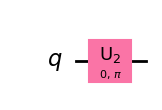

In [ ]:
qc.data[0].operation.definition.draw('mpl')

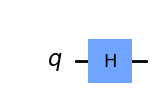

In [ ]:
qc = QuantumCircuit(1)
qc.append(
    HGate(),
    [0]
)
qc.draw('mpl')

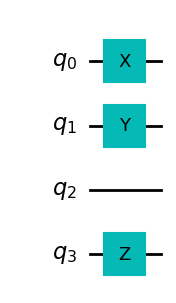

In [ ]:
qc_a = QuantumCircuit(4)
qc_a.x(0)

qc_b = QuantumCircuit(2, name = 'qc_b')
qc_b.y(0)
qc_b.z(1)

ckt_combined = qc_a.compose(qc_b, qubits=[1,3])
ckt_combined.draw('mpl')

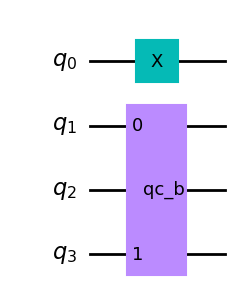

In [ ]:
inst = qc_b.to_instruction()
qc_a.append(inst, [1,3])
qc_a.draw('mpl')

/usr/local/lib/python3.10/dist-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


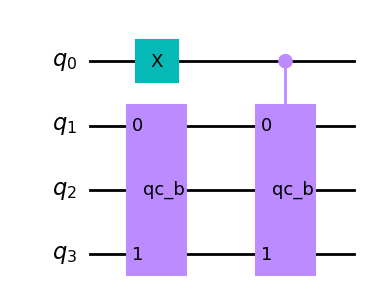

In [ ]:
gate = qc_b.to_gate().control()
qc_a.append(gate, [0, 1, 3])
qc_a.draw('mpl')

/usr/local/lib/python3.10/dist-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


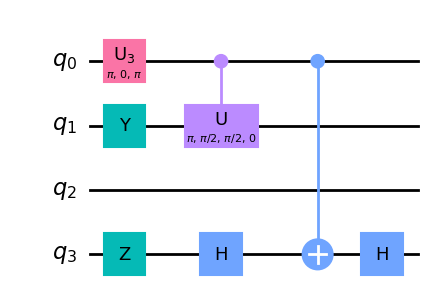

In [ ]:
qc_a.decompose().draw('mpl')
qc_a.docompose().draw('iqp')

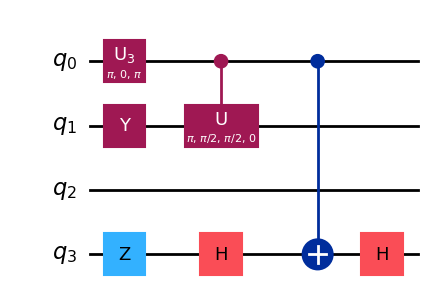

In [ ]:
qc_a.decompose().draw('mpl', style='iqp')

# Functionalities

In [ ]:
qubits = QuantumRegister(1, name='applyer')
clbits = ClassicalRegister(1, name='checker1')
clbits2 = ClassicalRegister(2, name='checker2')
circuit = QuantumCircuit(qubits, clbits, clbits2)



q_a = QuantumCircuit(reg_a)
q_a.initialize(2)

(q0,) = qubits
(c0,) = clbits
(c1) = clbits2
print(qubits)
print(clbits)
print(clbits2)

QuantumRegister(1, 'applyer')
ClassicalRegister(1, 'checker1')
ClassicalRegister(2, 'checker2')


In [ ]:
print(c0)
print(c1)

Clbit(ClassicalRegister(1, 'checker1'), 0)
ClassicalRegister(2, 'checker2')


/usr/local/lib/python3.10/dist-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


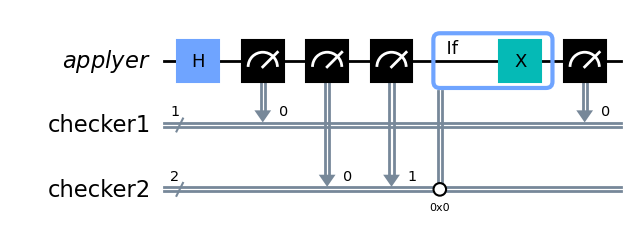

In [ ]:
circuit.h(q0)
circuit.measure(q0, c0)
circuit.measure(q0, c1)

with circuit.if_test((c0, 1)) and circuit.if_test((c1, 0)):
  circuit.x(q0)

circuit.measure(q0, c0)
circuit.draw('mpl')

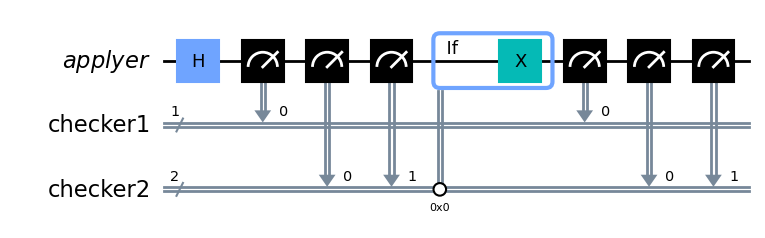

In [ ]:
circuit.measure(q0, c1)
circuit.draw('mpl')

In [ ]:
# backend = Aer.get_backend('aer_simulator')
backend = AerSimulator()
# job = execute(circuit, backend, shots=1024)  # Specify number of shots
# result = job.result()

result = backend.run(circuit).result()

print(result.get_counts())

# result = Sampler().run(circuit).result()
# print(f' Length of Result List : {len(result.quasi_dists)}')
# print(f'Result : {result.quasi_dists[0]}')

{'11 1': 498, '00 1': 526}


In [ ]:
# counts = result.get_counts(circuit)
# print(counts)

In [ ]:
from qiskit.circuit.library import RealAmplitudes

In [ ]:
num_features = 10

In [ ]:
ansatz = RealAmplitudes(num_qubits=num_features, reps=3)
ansatz.decompose().draw(output="mpl", style="clifford", fold=20)